In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sys
print('Python version:', sys.version)
print('Pandas version:', pd.__version__)
print('Numpy version:', np.__version__)
print('Matplotlib version:', matplotlib.__version__)

Python version: 3.12.16 (main, Oct 26 2026, 14:10:56) [MSC v.1944 64 bit (AMD64)]
Pandas version: 3.1.1
Numpy version: 2.5.5
Matplotlib version: 3.11.2


In [2]:
# 标准库
import sqlite3  # 读取数据库的
import json  
import joblib  # 保存模型和整条pipeline

# 数据分析三件套
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn工具套件
from sklearn.model_selection import train_test_split      # 划分数据集
from sklearn.pipeline import Pipeline                      # 搭建流水线 
from sklearn.compose import ColumnTransformer              # 数值列、类别列分开处理 
from sklearn.impute import SimpleImputer                   # 填补缺失值 
from sklearn.preprocessing import OneHotEncoder            # 对数据做独热编码 
from sklearn.preprocessing import StandardScaler           # 对数据做标准化 
from sklearn.linear_model import LogisticRegression        # 逻辑回归 
from sklearn.ensemble import RandomForestClassifier        # 随机森林 
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score # 三个常用指标 
from sklearn.metrics import confusion_matrix, classification_report # 混淆矩阵、分类报告 

In [3]:
# 定义常量
SEED = 42
DATA = '../data/'
DB = DATA + 'bank-marketing.db'
TARGET = '是否认购'          # 目标列在库里叫「是否认购」，取值是中文「是 / 否」

# 画图的约定
# ---- 画图约定：本讲所有的图都按这一套来，换图不用再调样式 ----
# 中文字体：西文 TeX Gyre Termes（接近论文排版），中文 思源宋体 Noto Serif CJK SC
plt.rcParams['font.family'] = ['TeX Gyre Termes','Noto Serif CJK SC']  # 中英文字体
plt.rcParams['mathtext.fontset'] = 'cm'  # 数学字体
plt.rcParams["axes.unicode_minus"] = False                  # 负号用 "-"，中文字体缺 "−" 时不会显示成方块
plt.rcParams["figure.dpi"] = 130                            # Notebook 里看得清，又不至于太大
plt.rcParams["font.size"] = 11                              # 字号比默认的 10 大一号，投屏也看得清
plt.rcParams["axes.spines.top"] = False                     # 去掉上边框、右边框，图更干净
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True                            # 浅色网格，读数方便
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

# 颜色只用这几种，每种颜色在全讲里只表示一件事
C_NEG = "#3E8EDE"                                           # 蓝：阴性（label = 0）/ 正常的值
C_POS = "#EC7FA3"                                           # 粉：阳性（label = 1）
C_LR = "#3E8EDE"                                            # 蓝：逻辑回归
C_RF = "#F39A55"                                            # 橙：随机森林
C_BAD = "#C94E78"                                           # 深粉：可疑的值、要注意的地方
C_REF = "#8591A7"                                           # 灰：参照线（随机、上限、阈值）

## 1. 认识数据：这张表里有什么

两个前提先钉死，后面所有判断都建立在它们上面：

- **预测什么**：客户会不会认购定期存款，对应「是否认购」这一列（是 / 否），认购率 11.70%。
- **什么时候预测**：**这通电话打出去之前**。这条比模型选择重要得多——凡是通话过程中或通话之后才能知道的信息，都不能进模型。第 5 节会拿这条去筛「通话时长」。

数据只有一张表「银行营销数据」，45,211 行、17 列，没有缺失值，也没有完全重复的行。这是一份已经清洗过的成品数据，所以这一节的重点不是修补，而是**看懂每一列在业务里到底是什么**。

In [4]:
# 库里有什么表、每张表多少行多少列：SQLite 的目录表 sqlite_master 里登记着所有表
with sqlite3.connect(DB) as conn:                            # 离开这一段自动关连接
    tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", conn)
    for name in tables["name"]:                              # 逐张表看：列有哪些、行有多少
        cols = pd.read_sql(f'PRAGMA table_info("{name}")', conn)                # 一行一列：列名、类型、是否可空……
        n = pd.read_sql(f'SELECT COUNT(*) AS n FROM "{name}"', conn)["n"][0]    # 取出唯一那个数：行数
        print(f"{name:<8}{n:>8,} 行  {len(cols):>2} 列：", "、".join(cols["name"]))

银行营销数据    45,211 行  17 列： 年龄、职业、婚姻状态、教育程度、是否信贷违约、账户余额、住房贷款、个人贷款、联系方式、联系日期、联系月份、通话时长、本次联系次数、距上次联系天数、历史联系次数、上次营销结果、是否认购


In [5]:
with sqlite3.connect(DB) as conn:
    df = pd.read_sql('SELECT * FROM "银行营销数据"', conn)   # 只有一张表，直接全量读进来

# 常量区的 TARGET 已指向真实列名「是否认购」，库里取值是中文「是 / 否」；
# 这里派生一个 0/1 的 label 列，后面所有统计都按「是 = 1」算，和中文列名解耦。
df["label"] = (df[TARGET] == "是").astype(int)

print(df.shape)
df.head(3).T                                                 # 转置：一列一行，字段名才看得清

(45211, 18)


,0,1,2
年龄,58,44,33
职业,管理人员,技术人员,企业家
婚姻状态,已婚,未婚,已婚
教育程度,高等教育,中学,中学
是否信贷违约,否,否,否
账户余额,2143,29,2
住房贷款,是,是,是
个人贷款,否,否,是
联系方式,未知,未知,未知
联系日期,5,5,5


In [6]:
# 结构体检：类型、缺失、每列有几个不同取值；再看有没有完全重复的行
profile = pd.DataFrame({
    "类型": df.drop(columns="label").dtypes.astype(str),
    "缺失数": df.drop(columns="label").isna().sum(),
    "取值个数": df.drop(columns="label").nunique(),
})
print("完全重复的行:", df.drop(columns="label").duplicated().sum())
profile

完全重复的行: 0


,类型,缺失数,取值个数
年龄,int64,0,77
职业,str,0,12
婚姻状态,str,0,3
教育程度,str,0,4
是否信贷违约,str,0,2
账户余额,int64,0,7168
住房贷款,str,0,2
个人贷款,str,0,2
联系方式,str,0,3
联系日期,int64,0,31


体检结果：17 列里 7 列是数值（年龄、账户余额、联系日期、通话时长、本次联系次数、距上次联系天数、历史联系次数），10 列是文字。

文字列里有三列带「未知」：职业 288 条（0.64%）、教育程度 1,857 条（4.11%）、联系方式 13,020 条（28.80%）。**这不是缺失值**，是数据采集时就填了「未知」。两者处理方式完全不同：缺失值要填补，而「未知」是一个有信息量的档位——第 4 节会看到，联系方式「未知」这一档的认购率只有 4.07%。把它当空值填掉，等于把这一万三千人最明显的特征抹掉。

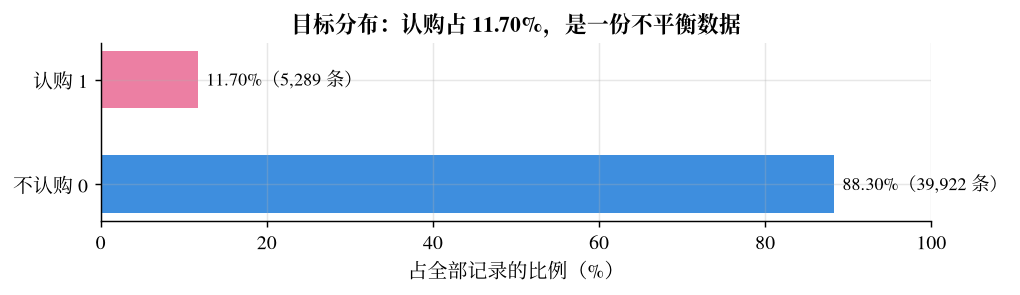

In [7]:
share = df["label"].value_counts(normalize=True).sort_index()     # 0 在前、1 在后
counts = df["label"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 2.4))
ax.barh(["不认购 0", "认购 1"], share.values * 100, color=[C_NEG, C_POS], height=0.55)
for i, (v, n) in enumerate(zip(share.values, counts.values)):
    ax.text(v * 100 + 1, i, f"{v:.2%}（{n:,} 条）", va="center", fontsize=10)
ax.set_xlim(0, 100)
ax.set_xlabel("占全部记录的比例（%）")
ax.set_title(f"目标分布：认购占 {share[1]:.2%}，是一份不平衡数据")
plt.tight_layout()
plt.show()

认购 5,289 条、占 11.70%；不认购 39,922 条、占 88.30%，约 1 : 7.6。

这意味着：**一个把所有客户都判成「不认购」的模型，准确率就有 88.30%**。所以后面看模型不能只看准确率，要看认购这一类抓得准不准、抓得全不全。分析阶段对应的做法是看「各档的认购率」，而不是看「各档有多少人」。

## 2. 单变量画像：17 列逐个过一遍

先不看目标，只看每一列自己长什么样。重点盯三件事：**长尾**（均值被拉走）、**负值**（是真状态还是录错）、**哨兵值**（用特殊数字表示「没有」）。

In [8]:
NUM_COLS = ["年龄", "账户余额", "通话时长", "本次联系次数", "历史联系次数", "距上次联系天数", "联系日期"]

# 1% 和 99% 分位一定要看：均值容易被长尾拉走，分位数才代表「大多数人在哪」
df[NUM_COLS].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T[
    ["mean", "std", "min", "1%", "25%", "50%", "75%", "99%", "max"]].round(1)

,mean,std,min,1%,25%,50%,75%,99%,max
年龄,40.9,10.6,18.0,23.0,33.0,39.0,48.0,71.0,95.0
账户余额,1362.3,3044.8,-8019.0,-627.0,72.0,448.0,1428.0,13164.9,102127.0
通话时长,258.2,257.5,0.0,11.0,103.0,180.0,319.0,1269.0,4918.0
本次联系次数,2.8,3.1,1.0,1.0,1.0,2.0,3.0,16.0,63.0
历史联系次数,0.6,2.3,0.0,0.0,0.0,0.0,0.0,8.9,275.0
距上次联系天数,40.2,100.1,-1.0,-1.0,-1.0,-1.0,-1.0,370.0,871.0
联系日期,15.8,8.3,1.0,2.0,8.0,16.0,21.0,31.0,31.0


七个数值列，五个地方值得记下来：

1. **账户余额有负值**：最低 −8,019，负余额 3,766 条（8.33%）。透支在银行业务里是真实状态，不是录入错误，不能当异常删掉；但它和「没钱的客户」含义不同，建模时值得单独标一个「是否透支」。
2. **通话时长极度右偏**：中位数 180 秒，99% 分位 1,269 秒，最长 4,918 秒（82 分钟）。均值 258 秒被长尾拉高了。
3. **本次联系次数、历史联系次数都是长尾**：中位数分别是 2 次和 0 次，最大到 63 次和 275 次，多半是极少数被反复联系的客户。
4. **距上次联系天数的中位数是 −1**：这不是天数，是「从未联系过」的哨兵值，占 81.74%。第 3 节专门处理。
5. **联系日期只是月内的第几天**（1~31），不是完整日期。库里没有年份，做不了真正的时间趋势，只能看月内分布。

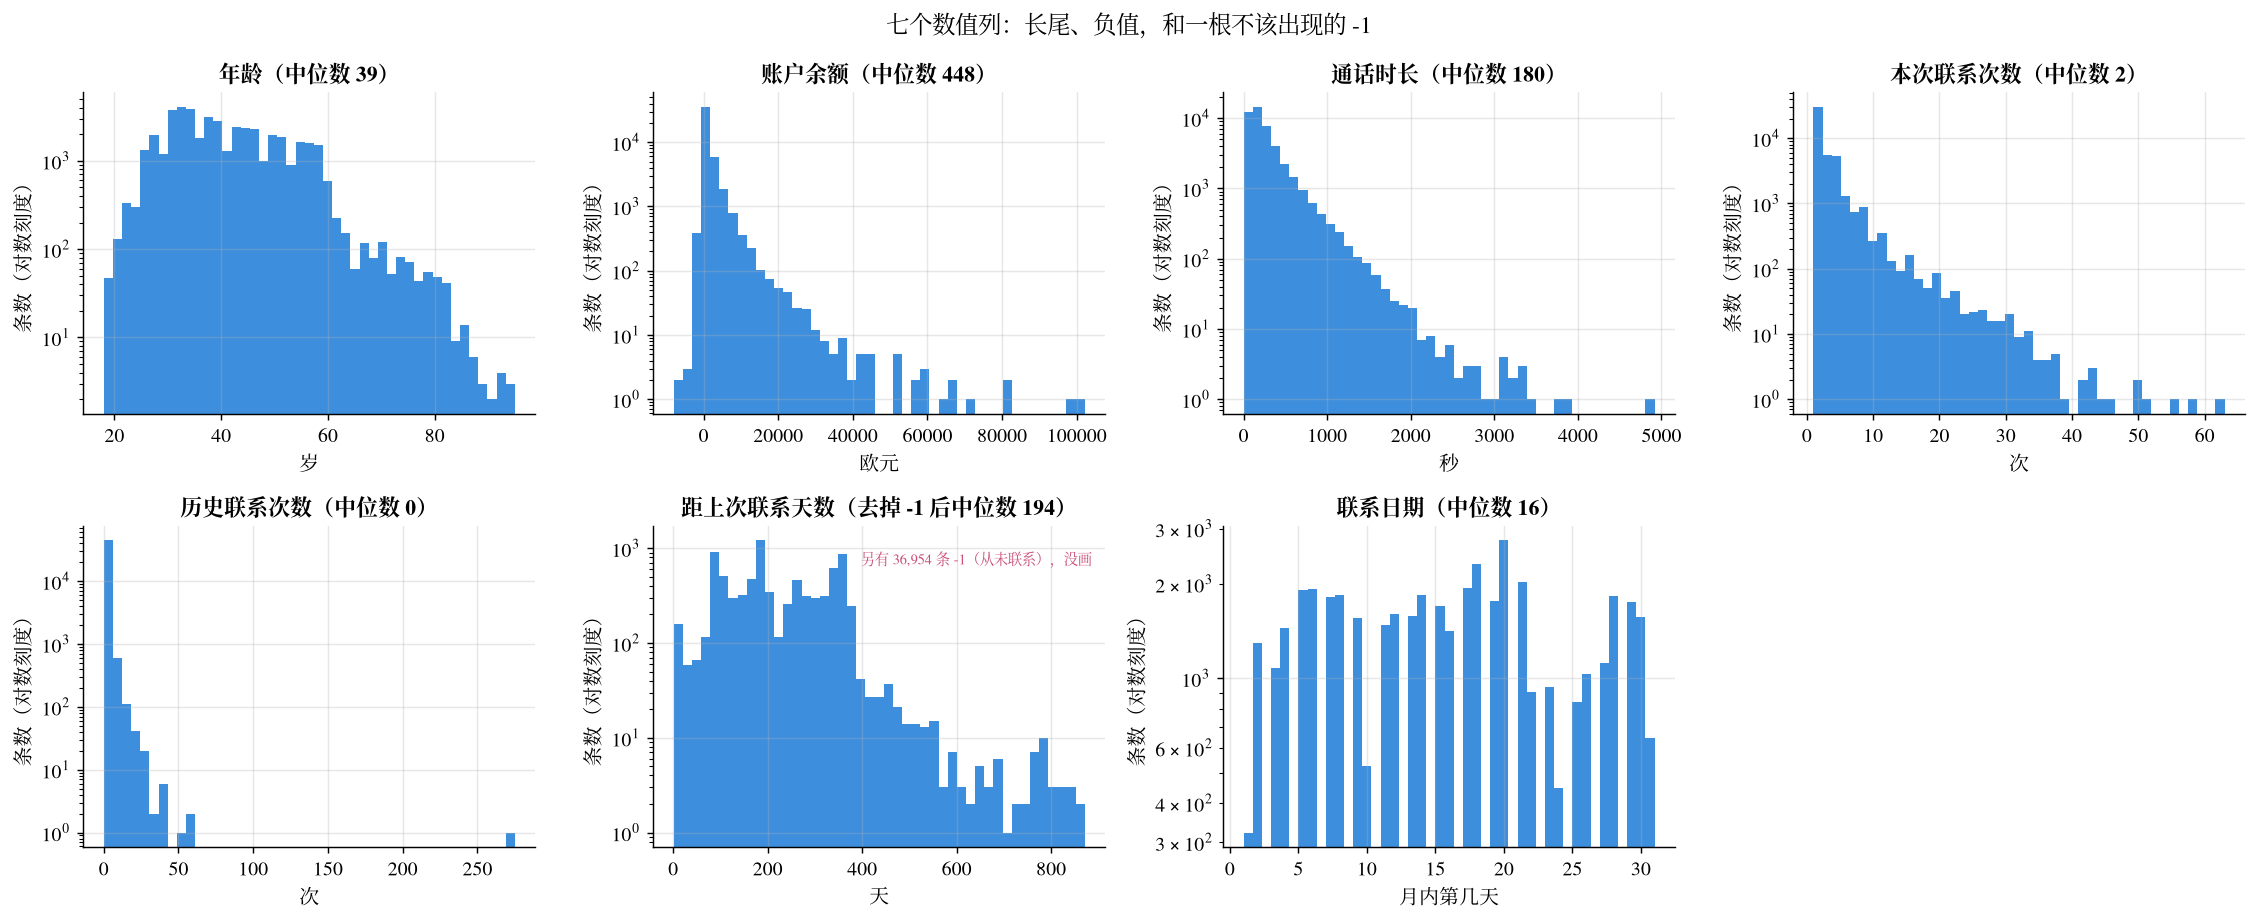

In [9]:
units = {"年龄": "岁", "账户余额": "欧元", "通话时长": "秒", "本次联系次数": "次",
         "历史联系次数": "次", "距上次联系天数": "天", "联系日期": "月内第几天"}

fig, axes = plt.subplots(2, 4, figsize=(17.5, 7.2))     # 7 列要 8 格，多出来那格最后关掉
for ax, col in zip(axes.flat, NUM_COLS):
    s = df[col]
    note = ""
    if col == "距上次联系天数":          # -1 是「从未联系」的哨兵值，混进直方图会凭空多出一根负数的柱子
        s = s[s != -1]
        note = f"另有 {(df[col] == -1).sum():,} 条 -1（从未联系），没画"
    ax.hist(s, bins=45, color=C_NEG)
    ax.set_yscale("log")                 # 长尾会把大部分柱子压成 1 像素，取对数才看得见
    ax.set_title(f"{col}（{'去掉 -1 后' if note else ''}中位数 {s.median():g}）")
    ax.set_xlabel(units[col])
    ax.set_ylabel("条数（对数刻度）")
    if note:
        ax.text(0.97, 0.88, note, transform=ax.transAxes, ha="right", fontsize=8, color=C_BAD)
axes.flat[-1].axis("off")                # 第 8 格没有数据，关掉，别留一个空框
fig.suptitle("七个数值列：长尾、负值，和一根不该出现的 -1", fontsize=13)
plt.tight_layout()
plt.show()

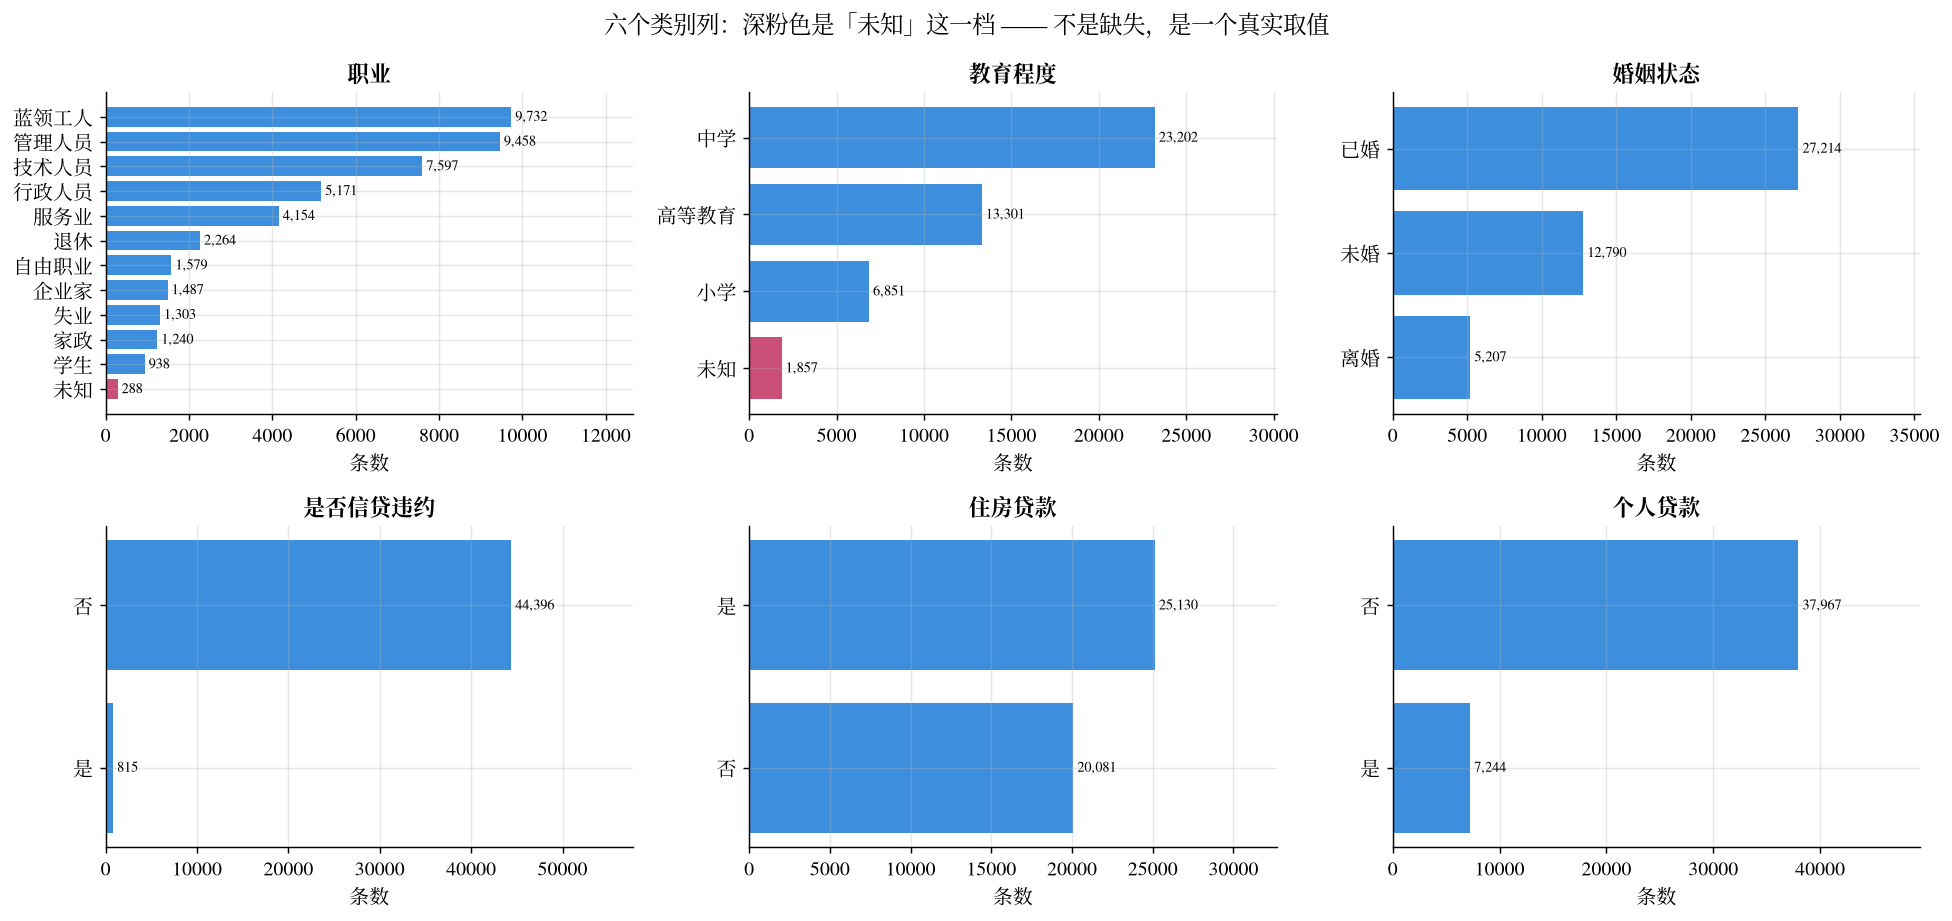

In [10]:
CAT_COLS = ["职业", "教育程度", "婚姻状态", "是否信贷违约", "住房贷款", "个人贷款"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7.2))
for ax, col in zip(axes.flat, CAT_COLS):
    vc = df[col].value_counts().sort_values()                       # 从小到大，barh 画出来最多的在最上面
    colors = [C_BAD if v == "未知" else C_NEG for v in vc.index]     # 「未知」单独标色，它不是缺失
    ax.barh(vc.index, vc.values, color=colors)
    for i, v in enumerate(vc.values):
        ax.text(v, i, f" {v:,}", va="center", fontsize=8)
    ax.set_xlim(0, vc.max() * 1.3)                                  # 右边留白给数字
    ax.set_title(col)
    ax.set_xlabel("条数")
fig.suptitle("六个类别列：深粉色是「未知」这一档 —— 不是缺失，是一个真实取值", fontsize=13)
plt.tight_layout()
plt.show()

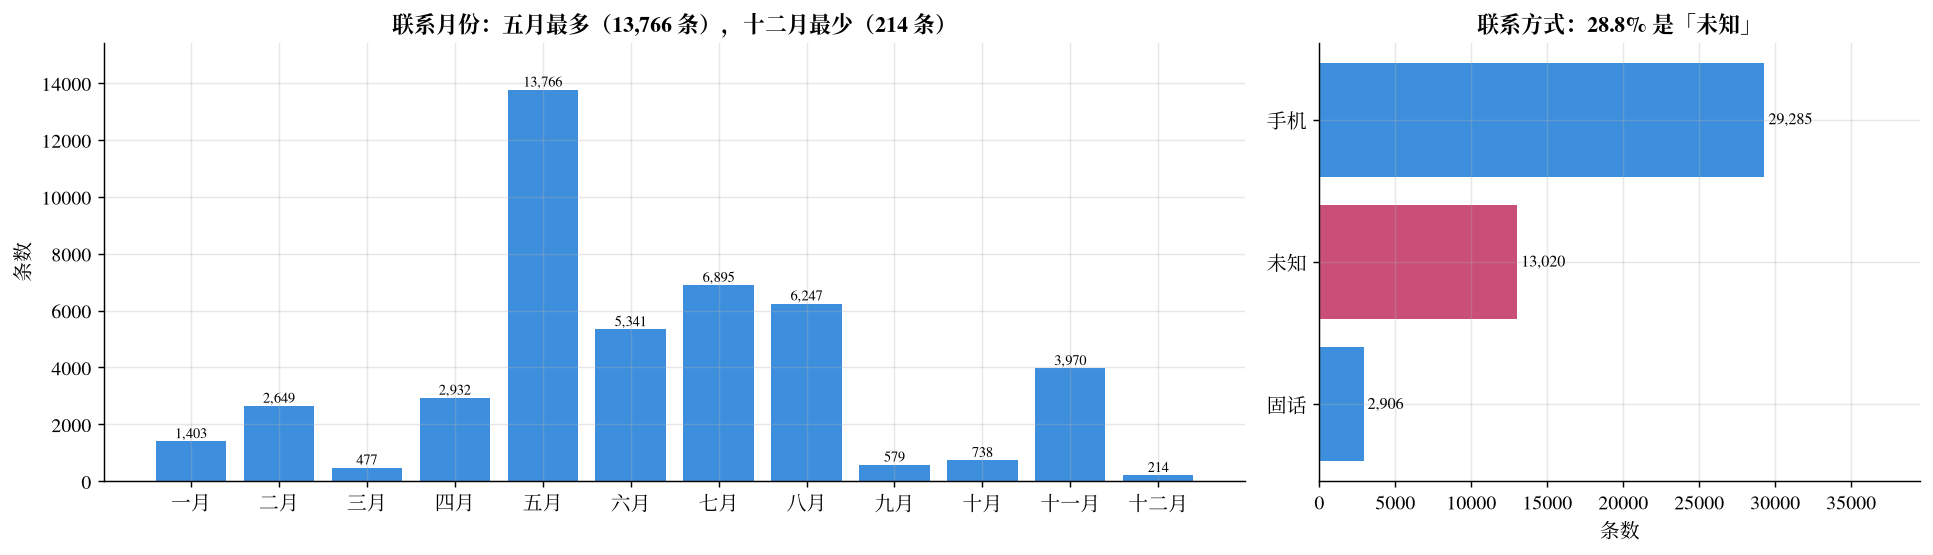

In [11]:
MONTHS = ["一月", "二月", "三月", "四月", "五月", "六月",
          "七月", "八月", "九月", "十月", "十一月", "十二月"]   # 月份按自然顺序排，按频数排就看不出季节性

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.9, 1]})

m = df["联系月份"].value_counts().reindex(MONTHS)
axes[0].bar(MONTHS, m.values, color=C_NEG)
for i, v in enumerate(m.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
axes[0].set_title("联系月份：五月最多（13,766 条），十二月最少（214 条）")
axes[0].set_ylabel("条数")
axes[0].set_ylim(0, m.max() * 1.12)                             # 顶上留白，柱子的数字才不会被裁掉

c = df["联系方式"].value_counts().sort_values()
axes[1].barh(c.index, c.values, color=[C_BAD if v == "未知" else C_NEG for v in c.index])
for i, v in enumerate(c.values):
    axes[1].text(v, i, f" {v:,}", va="center", fontsize=9)
axes[1].set_xlim(0, c.max() * 1.35)
axes[1].set_title("联系方式：28.8% 是「未知」")
axes[1].set_xlabel("条数")
plt.tight_layout()
plt.show()

## 3. 哨兵值：`-1` 不是天数

「距上次联系天数」的最小值是 −1，占 81.74%。负数天数没有业务含义，它其实是**用 −1 表示「从来没有联系过」**。这类值叫哨兵值（sentinel value）——比缺失值更麻烦，因为它长得像正常数字，直接扔进模型会被当成「上次是负 1 天前联系的」。

怎么确认这个判断？用另一列做交叉验证：如果 −1 真是「从未联系」，那么这些人的「上次营销结果」应该全是「未知」。

In [12]:
# ① 交叉验证：-1 那一组的上次营销结果，是不是全为「未知」
ct = pd.crosstab(df["距上次联系天数"].eq(-1).rename("距上次联系天数 = -1"),
                 df["上次营销结果"], margins=True, margins_name="合计")
print(ct.to_string())

# ② 反过来查不自洽的少数：有上次联系天数，结果却记成「未知」
odd = df[(df["距上次联系天数"] != -1) & (df["上次营销结果"] == "未知")]
print(f"\n有上次联系天数、结果却是「未知」的记录：{len(odd)} 条")
display(odd[["距上次联系天数", "历史联系次数", "本次联系次数", TARGET]])

# ③ 派生正式要用的列：被联系过 = 1，从未联系 = 0
df["是否被联系过"] = df["距上次联系天数"].ne(-1).astype(int)
df.groupby("是否被联系过")["label"].agg(["size", "mean"]).round(4)

上次营销结果          其他    失败    成功     未知     合计
距上次联系天数 = -1                                
False         1840  4901  1511      5   8257
True             0     0     0  36954  36954
合计            1840  4901  1511  36959  45211

有上次联系天数、结果却是「未知」的记录：5 条


,距上次联系天数,历史联系次数,本次联系次数,是否认购
40658,98,1,4,是
41821,168,5,1,否
42042,188,2,1,是
43978,416,2,3,否
45021,528,7,3,否


,size,mean
是否被联系过,,
0,36954,0.0916
1,8257,0.2307


结论很干净：36,954 条 −1 **全部**对应「上次营销结果 = 未知」；而「未知」共有 36,959 条，多出来的 5 条填了真实天数。

这 5 条是两个字段维护口径不一致留下的痕迹（占 0.01%），量太小，不值得单独修，但要在报告里记一笔：**用「上次营销结果」筛人时，会漏掉这 5 条实际联系过的记录**。

派生口径：`是否被联系过 = 距上次联系天数 != -1`。这样得到 36,954 条「从未联系」（认购率 9.16%）和 8,257 条「联系过」（认购率 23.07%）。按你定的方案，原列保留不动，两列都在表里。

## 4. 这些特征和「认购」有没有关系

单变量看完，进入这一步的核心问题：**每一列能不能把认购的人和不认购的人分开**。数值列用密度图看位置差，类别列看每一档的认购率——后者比频数更有信息量，因为在 11.70% 的基线下，一个档位 30% 的认购率才是信号。

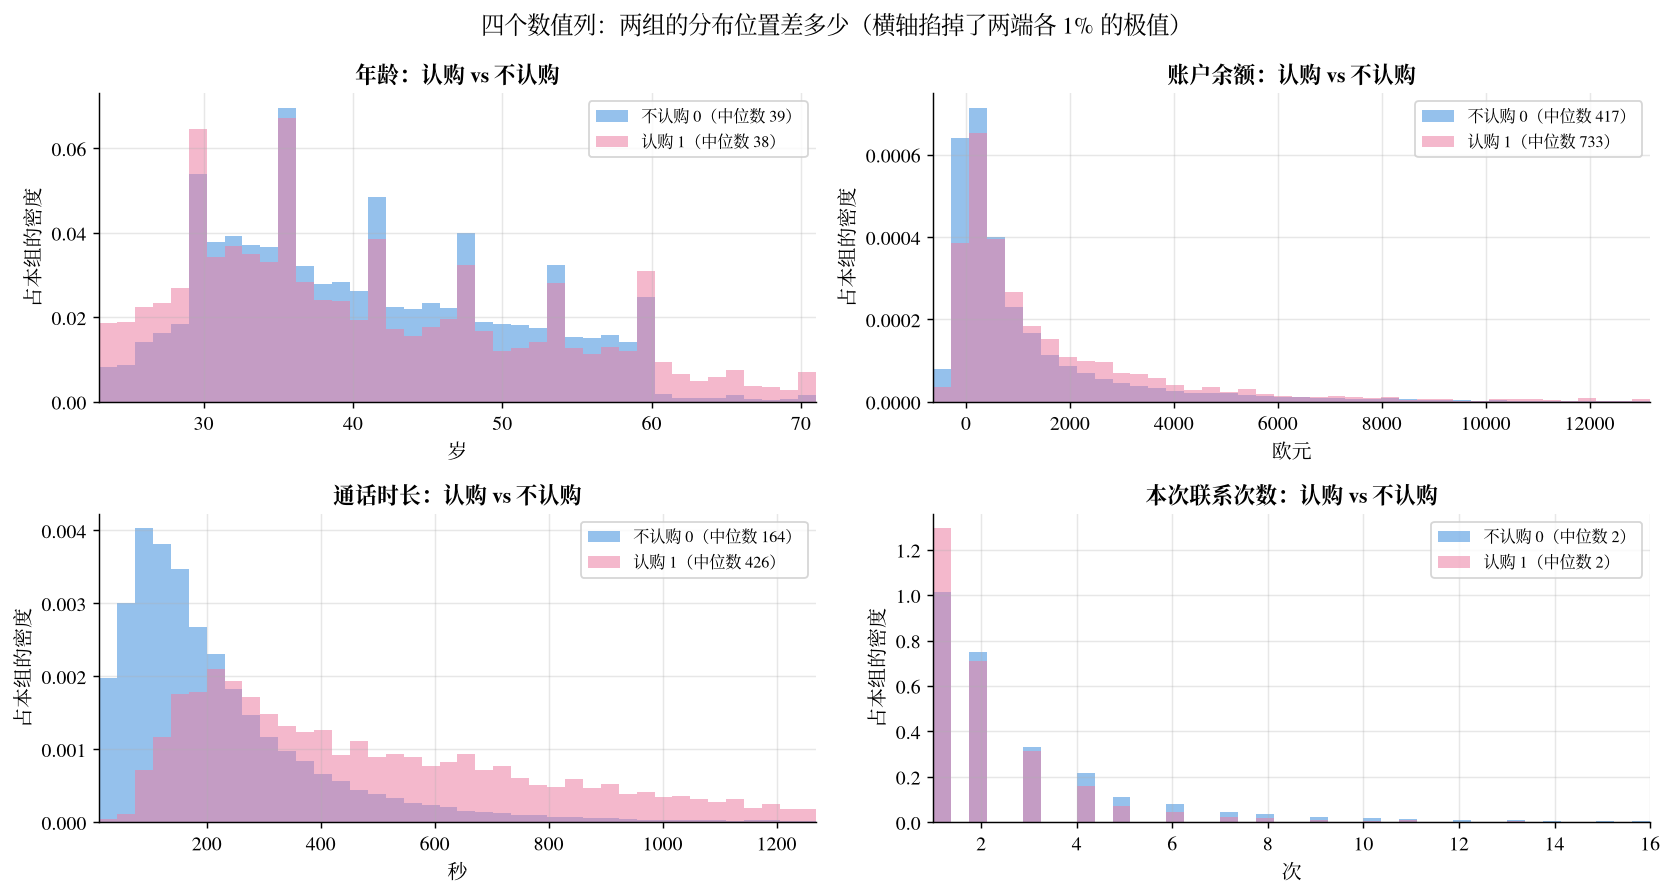

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, col in zip(axes.flat, ["年龄", "账户余额", "通话时长", "本次联系次数"]):
    lo, hi = df[col].quantile([0.01, 0.99])      # 掐掉两端各 1%，否则余额的十万级极值会把图压扁
    edges = np.linspace(lo, hi, 41)
    for v, color, text in [(0, C_NEG, "不认购 0"), (1, C_POS, "认购 1")]:
        part = df.loc[df["label"] == v, col]
        ax.hist(part, bins=edges, density=True, alpha=0.55, color=color,   # density：两组人数差 7.6 倍，按比例比才公平
                label=f"{text}（中位数 {part.median():g}）")
    ax.set_xlim(lo, hi)
    ax.set_xlabel(units[col])
    ax.set_ylabel("占本组的密度")
    ax.set_title(f"{col}：认购 vs 不认购")
    ax.legend(fontsize=9)
fig.suptitle("四个数值列：两组的分布位置差多少（横轴掐掉了两端各 1% 的极值）", fontsize=13)
plt.tight_layout()
plt.show()

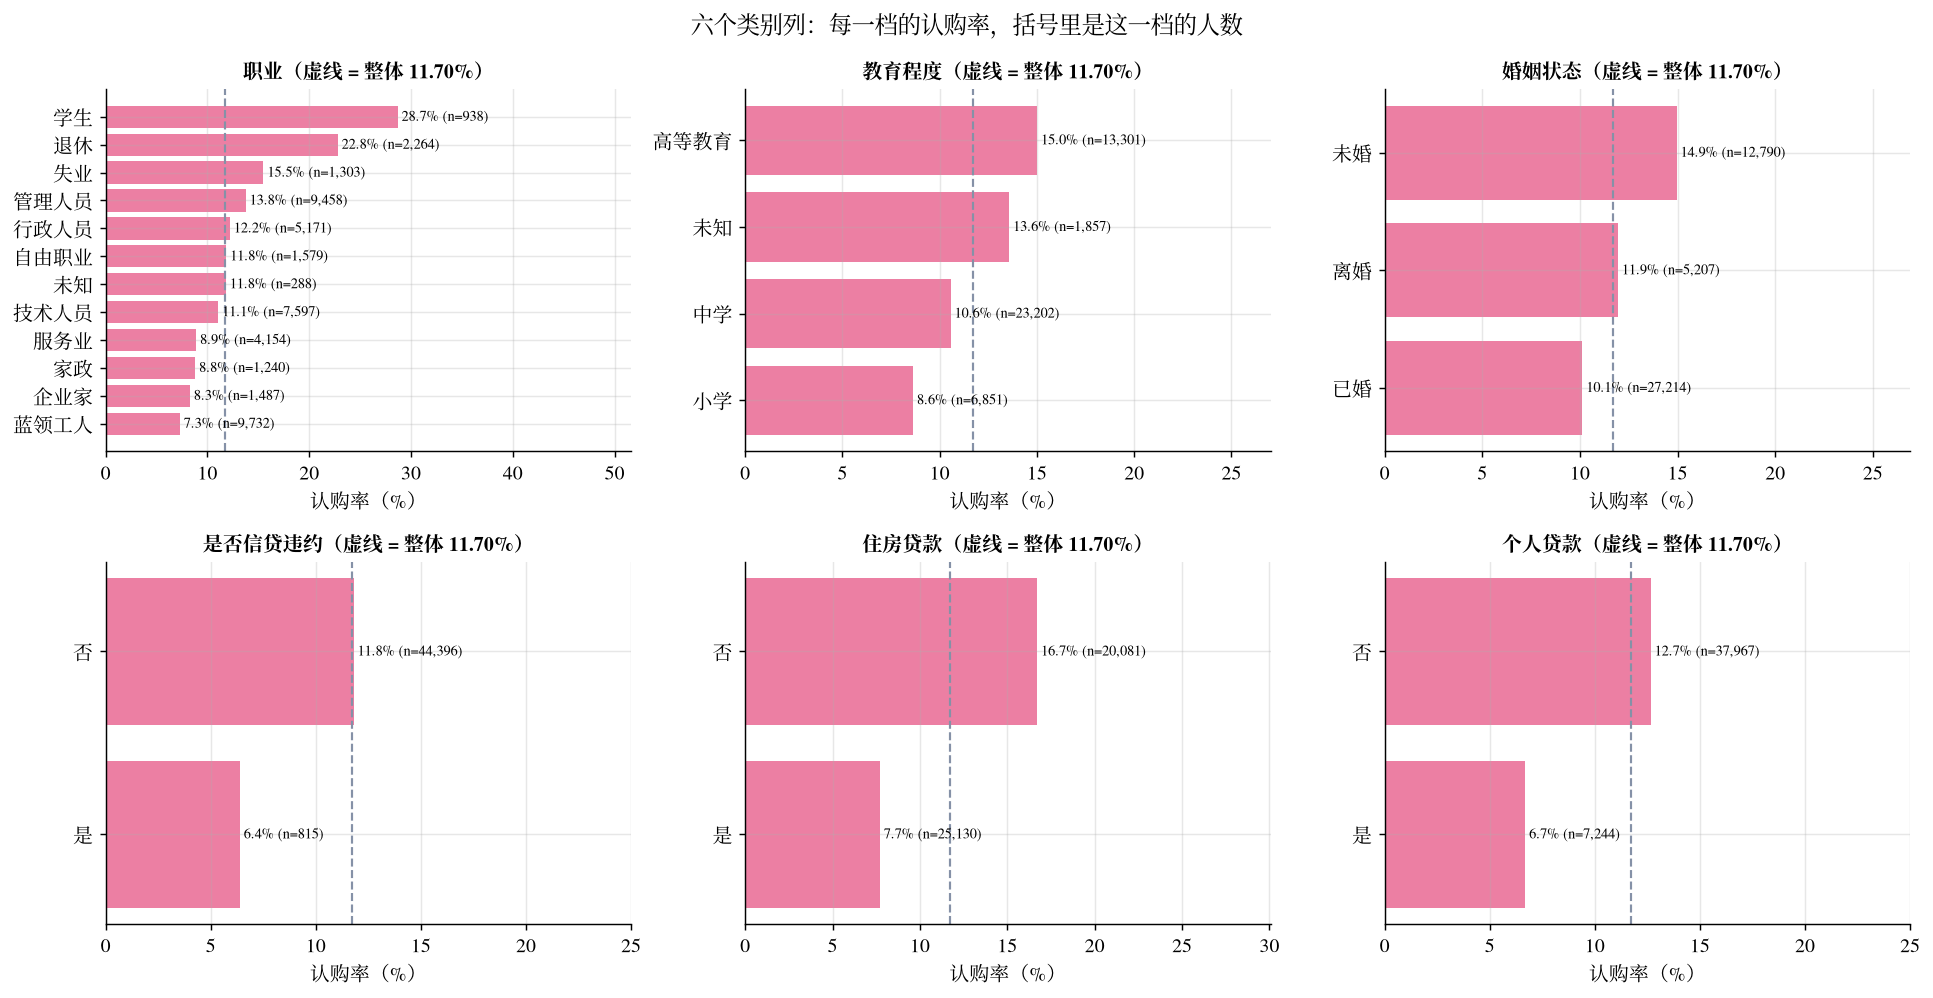

In [14]:
base = df["label"].mean()                                    # 整体认购率，每张图都画一条做参照
fig, axes = plt.subplots(2, 3, figsize=(15, 7.8))
for ax, col in zip(axes.flat, CAT_COLS):
    g = df.groupby(col)["label"].agg(["size", "mean"]).sort_values("mean")
    ax.barh(g.index, g["mean"] * 100, color=C_POS)
    ax.axvline(base * 100, color=C_REF, linestyle="--", lw=1.2)          # 虚线 = 整体 11.70%
    for i, (n, m) in enumerate(zip(g["size"], g["mean"])):
        ax.text(m * 100, i, f" {m:.1%} (n={n:,})", va="center", fontsize=8)
    ax.set_xlim(0, max(g["mean"].max() * 100 * 1.8, 25))
    ax.set_title(f"{col}（虚线 = 整体 {base:.2%}）", fontsize=11)
    ax.set_xlabel("认购率（%）")
fig.suptitle("六个类别列：每一档的认购率，括号里是这一档的人数", fontsize=13)
plt.tight_layout()
plt.show()

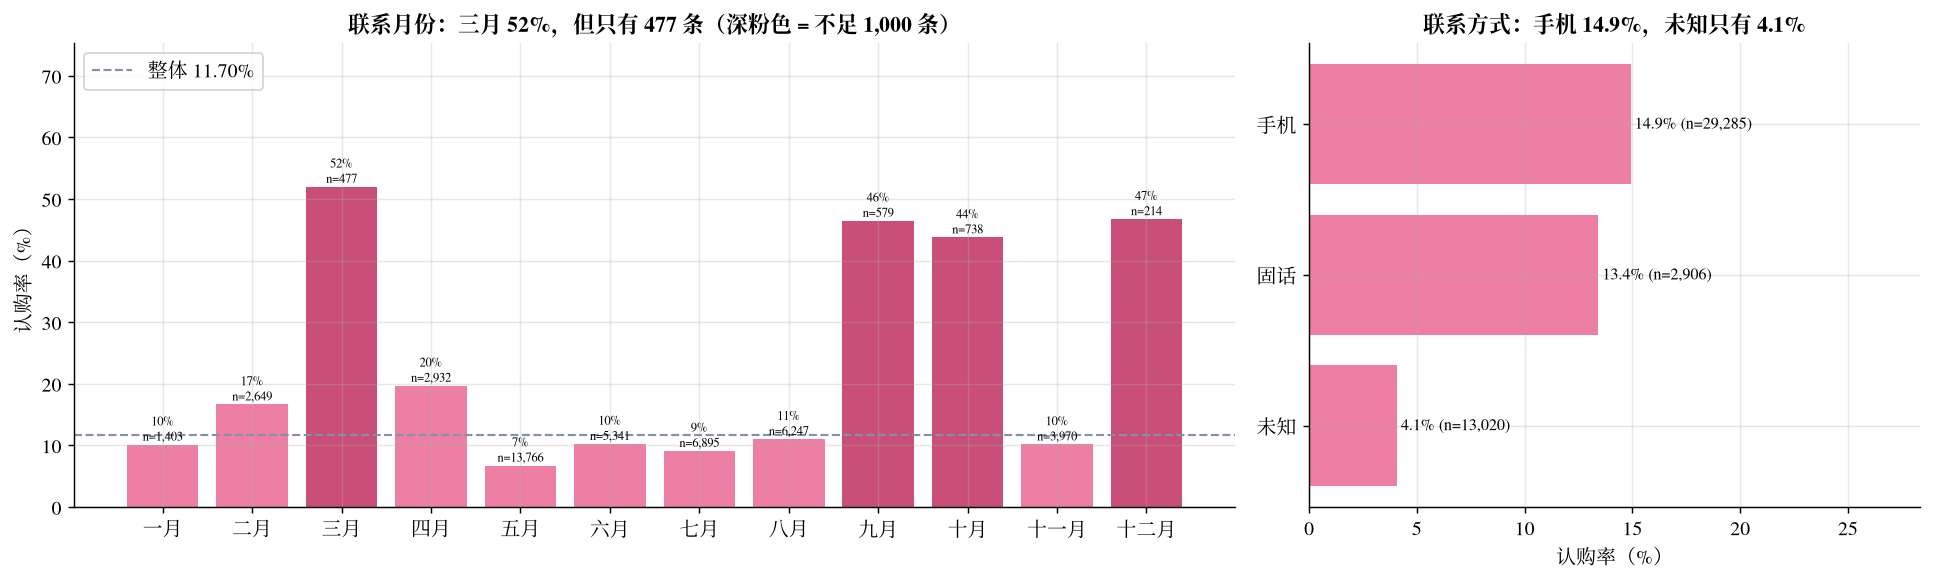

In [15]:
m = df.groupby("联系月份")["label"].agg(["size", "mean"]).reindex(MONTHS)   # 按自然月序，不按增长率排

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.9, 1]})

colors = [C_BAD if n < 1000 else C_POS for n in m["size"]]   # 样本不足 1,000 条的月份单独标色，别被高比例骗到
axes[0].bar(MONTHS, m["mean"] * 100, color=colors)
axes[0].axhline(df["label"].mean() * 100, color=C_REF, linestyle="--", lw=1.2,
                label=f"整体 {df['label'].mean():.2%}")
for i, (n, v) in enumerate(zip(m["size"], m["mean"])):
    axes[0].text(i, v * 100, f"{v:.0%}\nn={n:,}", ha="center", va="bottom", fontsize=7)
axes[0].set_ylim(0, m["mean"].max() * 100 * 1.45)
axes[0].set_title("联系月份：三月 52%，但只有 477 条（深粉色 = 不足 1,000 条）")
axes[0].set_ylabel("认购率（%）")
axes[0].legend(loc="upper left")

c = df.groupby("联系方式")["label"].agg(["size", "mean"]).sort_values("mean")
axes[1].barh(c.index, c["mean"] * 100, color=C_POS)
for i, (n, v) in enumerate(zip(c["size"], c["mean"])):
    axes[1].text(v * 100, i, f" {v:.1%} (n={n:,})", va="center", fontsize=9)
axes[1].set_xlim(0, c["mean"].max() * 100 * 1.9)
axes[1].set_title("联系方式：手机 14.9%，未知只有 4.1%")
axes[1].set_xlabel("认购率（%）")
plt.tight_layout()
plt.show()

是否认购        否     是     合计
上次营销结果                    
其他       1533   307   1840
失败       4283   618   4901
成功        533   978   1511
未知      33573  3386  36959
合计      39922  5289  45211


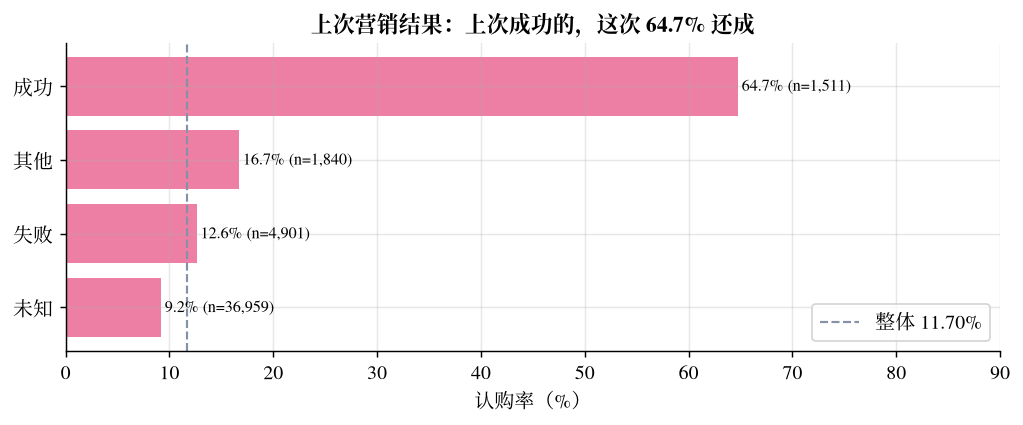

In [16]:
# 上次营销结果这一列，单独拿出来看：它是全表最强的单一信号
print(pd.crosstab(df["上次营销结果"], df[TARGET], margins=True, margins_name="合计").to_string())

g = df.groupby("上次营销结果")["label"].agg(["size", "mean"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(g.index, g["mean"] * 100, color=C_POS)
ax.axvline(df["label"].mean() * 100, color=C_REF, linestyle="--", lw=1.2,
           label=f"整体 {df['label'].mean():.2%}")
for i, (n, v) in enumerate(zip(g["size"], g["mean"])):
    ax.text(v * 100, i, f" {v:.1%} (n={n:,})", va="center", fontsize=9)
ax.set_xlim(0, 90)
ax.set_xlabel("认购率（%）")
ax.set_title("上次营销结果：上次成功的，这次 64.7% 还成")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

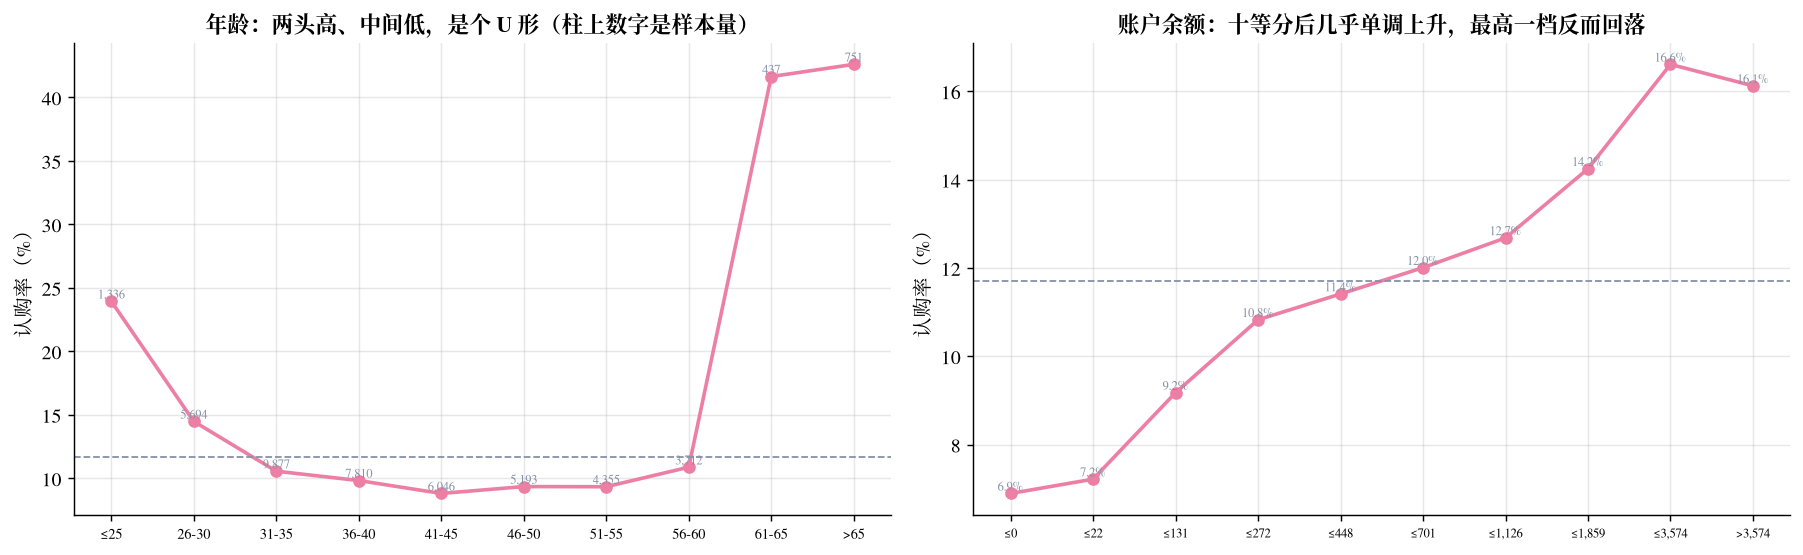

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

AGE_LABELS = ["≤25", "26-30", "31-35", "36-40", "41-45",
              "46-50", "51-55", "56-60", "61-65", ">65"]      # 区间标签写短，横轴才不会挤成一团
age_bin = pd.cut(df["年龄"], [17, 25, 30, 35, 40, 45, 50, 55, 60, 65, 100])
g = df.groupby(age_bin, observed=True)["label"].agg(["size", "mean"])
axes[0].plot(range(len(g)), g["mean"] * 100, marker="o", color=C_POS, lw=2)
axes[0].set_xticks(range(len(g)), AGE_LABELS, fontsize=8)
for i, (n, v) in enumerate(zip(g["size"], g["mean"])):
    axes[0].text(i, v * 100, f"{n:,}", ha="center", va="bottom", fontsize=7, color=C_REF)
axes[0].axhline(df["label"].mean() * 100, color=C_REF, linestyle="--", lw=1)
axes[0].set_title("年龄：两头高、中间低，是个 U 形（柱上数字是样本量）")
axes[0].set_ylabel("认购率（%）")

bal_bin = pd.qcut(df["账户余额"], 10, duplicates="drop")              # 十等分，每档人数尽量一样多
g2 = df.groupby(bal_bin, observed=True)["label"].agg(["size", "mean"])
axes[1].plot(range(len(g2)), g2["mean"] * 100, marker="o", color=C_POS, lw=2)
bal_labels = [f"≤{int(i.right):,}" for i in g2.index[:-1]] + [f">{int(g2.index[-1].left):,}"]
axes[1].set_xticks(range(len(g2)), bal_labels, fontsize=7)
for i, v in enumerate(g2["mean"]):
    axes[1].text(i, v * 100, f"{v:.1%}", ha="center", va="bottom", fontsize=7, color=C_REF)
axes[1].axhline(df["label"].mean() * 100, color=C_REF, linestyle="--", lw=1)
axes[1].set_title("账户余额：十等分后几乎单调上升，最高一档反而回落")
axes[1].set_ylabel("认购率（%）")
plt.tight_layout()
plt.show()

五张图放一起看，能读出四件事：

1. **最强的单一信号是「上次营销结果」**：上次成功的客户这次 64.73% 还成，是整体 11.70% 的 5.5 倍；上次失败的只有 12.61%，和整体差不多。也就是说「成功过一次」这件事本身有很强的延续性。
2. **年龄是 U 形，不是线性**：25 岁以下 24.0%、60~65 岁 41.6%、65 岁以上 42.6%，35~55 岁这一段只有 9% 左右。所以年龄的相关系数几乎为 0（−0.009），但它其实很有用——第 5 节会说明：**相关系数看不出 U 形关系**。
3. **有无房贷的差别很大**：没房贷 16.7%，有房贷 7.7%；个人贷款同样（12.7% vs 6.7%）。一个合理的解释是月供在压缩可支配收入，但这是推测，数据本身只能说明两者相关。
4. **月份上有极强的季节性**：三月 52.0%、十二月 46.7%、九月 46.5%、十月 43.8%，而五月只有 6.7%、七月 9.1%。但这四个月加起来才 2,008 条（4.4%），样本很小，**不能直接当作「三月打电话更容易成功」的结论**——它更可能反映「哪类客户被安排在哪些月份联系」。另外库里没有年份，跨年趋势完全看不到。

## 5. 建模前体检：相关、显著性、以及一条必须排除的列

上面是「看图说话」。这一步把判断量化，并且专门检查一件容易出人命的事：**有没有哪一列是事后才知道的**。

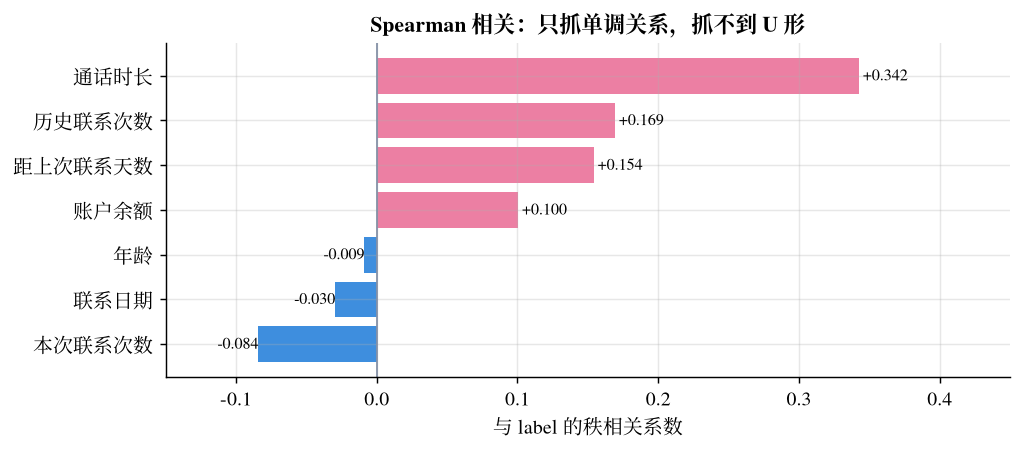

年龄的相关系数是 -0.009，但第 4 节的分箱图显示它是 U 形 —— 一正一负相互抵消了


In [18]:
corr = df[NUM_COLS + ["label"]].corr(method="spearman")["label"].drop("label").sort_values()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(corr.index, corr.values, color=[C_NEG if v < 0 else C_POS for v in corr.values])
for i, v in enumerate(corr.values):
    ax.text(v, i, f" {v:+.3f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color=C_REF, lw=1)
ax.set_xlim(-0.15, 0.45)
ax.set_xlabel("与 label 的秩相关系数")
ax.set_title("Spearman 相关：只抓单调关系，抓不到 U 形")
plt.tight_layout()
plt.show()

print("年龄的相关系数是 %.3f，但第 4 节的分箱图显示它是 U 形 —— 一正一负相互抵消了" % corr["年龄"])

In [19]:
from scipy.stats import chi2_contingency                    # 类别 × 目标：卡方检验 + Cramér's V

rows = []
for col in CAT_COLS + ["联系方式", "联系月份", "上次营销结果", "是否被联系过"]:
    tab = pd.crosstab(df[col], df["label"])
    chi2, p, dof, _ = chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))   # Cramér's V：0~1，越大关系越强
    rows.append({"列": col, "类别数": tab.shape[0], "卡方": round(chi2, 1),
                 "p 值": f"{p:.2e}", "Cramér's V": round(v, 3)})

pd.DataFrame(rows).sort_values("Cramér's V", ascending=False).reset_index(drop=True)

,列,类别数,卡方,p 值,Cramér's V
0,上次营销结果,4,4391.5,0.00e+00,0.312
1,联系月份,12,3061.8,0.00e+00,0.260
2,是否被联系过,2,1263.5,9.55e-277,0.167
3,联系方式,3,1035.7,1.25e-225,0.151
4,住房贷款,2,874.8,2.92e-192,0.139
5,职业,12,836.1,3.34e-172,0.136
6,教育程度,4,238.9,1.63e-51,0.073
7,个人贷款,2,209.6,1.67e-47,0.068
8,婚姻状态,3,196.5,2.15e-43,0.066
9,是否信贷违约,2,22.2,2.45e-06,0.022


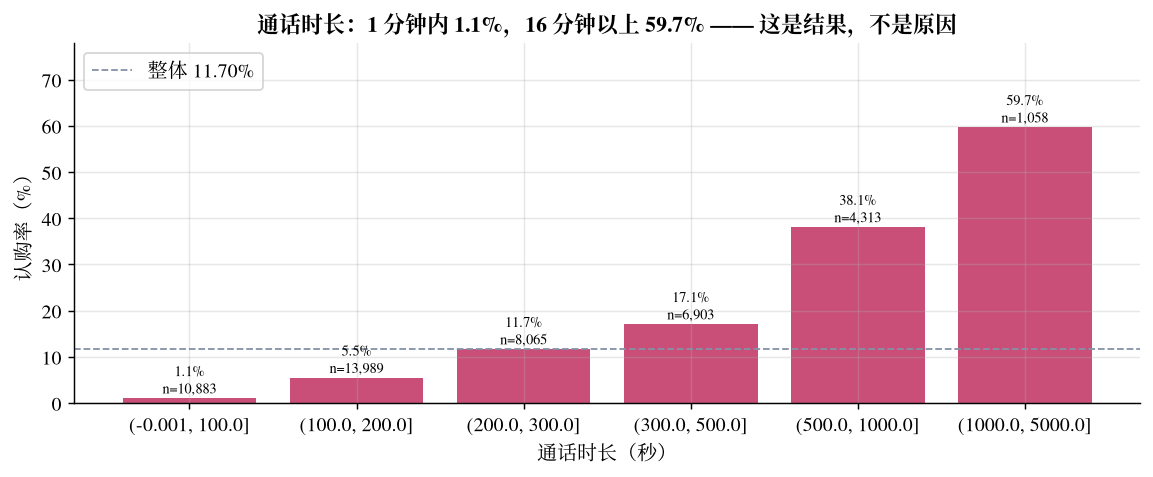

In [20]:
# 通话时长：如果是「通话前」的信息，各时长档的认购率不该有这么大跨度
dur_bin = pd.cut(df["通话时长"], [0, 100, 200, 300, 500, 1000, 5000], include_lowest=True)
g = df.groupby(dur_bin, observed=True)["label"].agg(["size", "mean"])

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar([str(i) for i in g.index], g["mean"] * 100, color=C_BAD)
for i, (n, v) in enumerate(zip(g["size"], g["mean"])):
    ax.text(i, v * 100, f"{v:.1%}\nn={n:,}", ha="center", va="bottom", fontsize=8)
ax.axhline(df["label"].mean() * 100, color=C_REF, linestyle="--", lw=1,
           label=f"整体 {df['label'].mean():.2%}")
ax.set_ylim(0, 78)
ax.set_xlabel("通话时长（秒）")
ax.set_ylabel("认购率（%）")
ax.set_title(f"通话时长：1 分钟内 {g['mean'].iloc[0]:.1%}，16 分钟以上 {g['mean'].iloc[-1]:.1%} —— 这是结果，不是原因")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

三个结论：

1. **通话时长必须排除**（Spearman 0.342，数值列里最高）。通话 1 分钟以内认购率 1.1%，16 分钟以上 59.7%。通话久不是因为客户会认购，而是因为客户有兴趣才聊得久——它是**通话的结果**，不是通话前能拿到的信息。把它放进模型，离线指标会非常漂亮，上线后拿不到这个值，模型直接废掉。
2. **「未知」不能当缺失填**：联系方式「未知」13,020 条、认购率 4.07%，是全表最低的一档。这不是数据质量问题，是一个真实的客群特征。
3. **联系日期可用性很低**：Spearman −0.030，而且它只是月内第几天，脱离年月没有业务含义。建议丢弃；月份保留，但要注意小样本月份。

关于卡方：每个 p 值都远小于 0.05，但这份数据有 4.5 万行，**样本一大，任何微小差异都会显著**，所以别看 p 值，看 Cramér's V 的大小——上次营销结果 0.312 最强；联系月份 0.260 次之（但混合了季节性，见上）；是否被联系过 0.167、联系方式 0.151、住房贷款 0.139、职业 0.136 属于中等；教育程度 0.073、个人贷款 0.068、婚姻状态 0.066、是否信贷违约 0.022 偏弱。偏弱不等于没用，独热编码后仍可能提供增量信息，只是别指望单靠它区分。

## 6. 小结：每一列该怎么处理

| 列 | 类型 | 与认购的关系（实测） | 建模建议 |
|---|---|---|---|
| 上次营销结果 | 类别 4 档 | 成功 64.7%（n=1,511）、其他 16.7%、失败 12.6%、未知 9.2%；V=0.312 全表最强 | 保留，是核心特征；「未知」与「从未联系」高度重叠，注意共线 |
| 是否被联系过 | 派生 0/1 | 联系过 23.1%（n=8,257）vs 从未 9.2%（n=36,954）；V=0.167 | 保留（已派生） |
| 联系月份 | 类别 12 档 | 三月 52.0%、十二月 46.7%、九月 46.5%，五月仅 6.7%；V=0.260 | 保留，但小样本月份（<600 条）考虑合并；缺年份是硬伤 |
| 联系方式 | 类别 3 档 | 手机 14.9%、固话 13.4%、未知 4.1%（n=13,020）；V=0.151 | 保留，「未知」独立成档，不能填 |
| 住房贷款 | 类别 2 档 | 无 16.7% vs 有 7.7%；V=0.139 | 保留 |
| 职业 | 类别 12 档 | 学生 28.7%、退休 22.8%，蓝领 7.3%、企业家 8.3%；V=0.136 | 保留，12 类独热后 12 列 |
| 教育程度 | 类别 4 档 | 高等教育 15.0%、未知 13.6%、中学 10.6%、小学 8.6%；V=0.073 | 保留；本身有序，可考虑序数编码 |
| 个人贷款 | 类别 2 档 | 无 12.7% vs 有 6.7%；V=0.068 | 保留 |
| 婚姻状态 | 类别 3 档 | 未婚 15.0%、离婚 12.0%、已婚 10.1%；V=0.066 | 保留，信号弱 |
| 是否信贷违约 | 类别 2 档 | 否 11.8%、是 6.4%（仅 815 条）；V=0.022 | 保留但样本极少，别单独解读 |
| 账户余额 | 数值（有负值） | 十等分后 6.9% → 16.6% 单调上升，最高档回落至 16.1%；ρ=0.100 | 保留；负余额占 8.33%，可加「是否透支」标记 |
| 年龄 | 数值 | U 形：≤25 岁 24.0%，60 岁以上 41.6%~42.6%，中间段约 9%；ρ=−0.009 | 保留；**必须分箱或让树模型处理**，直接线性用会失效 |
| 历史联系次数 | 数值 | ρ=0.169，长尾到 275 | 保留；考虑 log 变换或截尾 |
| 本次联系次数 | 数值 | ρ=−0.084，长尾到 63 | 保留；联系越多越难成，方向合理 |
| 距上次联系天数 | 数值 + 哨兵 | 有值组 23.1% vs 无值组 9.2%；ρ=0.154 | 保留原列可，但 −1 必须处理；已另派生 0/1 列 |
| 通话时长 | 数值 | ρ=0.342 最高，1 分钟内 1.1% → 16 分钟以上 59.7% | **排除**：通话结束后才知道，属于结果泄漏 |
| 联系日期 | 数值（月内第几天） | ρ=−0.030 | 丢弃：脱离年月无业务含义 |

一句话总结这份数据的形状：**它是一份「上一次联系的结果强烈预示这一次结果」的数据**——上次成功 64.7%、联系过 23.1%、没联系过 9.2%。模型能学到的，主要是这个延续性，再加上职业、教育、贷款、余额这些人口与财务特征做细分。

建模阶段要处理的三件事已经清楚了：排除通话时长、把「未知」保留成独立档位、给年龄做分箱（或交给树模型自己找 U 形）。